# Decision Tree Regressor

Same recursive splitting as the classifier (`15_decision_tree`), but for a continuous target:

- a split is chosen to minimize the squared error of the two sides (variance reduction)
- a leaf predicts the **mean** of its training targets, so predictions are piecewise constant

Splits are found in one pass per feature using cumulative sums over the sorted values, so a fit is O(n log n) per feature rather than re-scanning for every threshold. This tree is also the building block of `22_gradient_boosting`.

`max_depth` controls the bias/variance trade-off: shallow trees underfit, deep trees memorize noise.

## Usage

```python
# (the class is defined in the Implementation section below)

model = DecisionTreeRegressor(max_depth=5).fit(X_train, y_train)
preds = model.predict(X_test)
```

This notebook is self-contained: the explanation, the implementation, the visuals, the scikit-learn check and the tests are all here.

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})

## Implementation

The whole algorithm, as a plain Python class (numpy only).

In [2]:
import numpy as np


class DecisionTreeRegressor:
    """CART regression tree: each split minimizes squared error, each leaf predicts the mean."""

    def __init__(self, max_depth=5, min_samples_split=2):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.root = None

    def fit(self, X, y):
        self.root = self._grow(np.asarray(X, dtype=float), np.asarray(y, dtype=float), depth=0)
        return self

    def predict(self, X):
        return self._predict(self.root, np.asarray(X, dtype=float))

    def _grow(self, X, y, depth):
        if depth >= self.max_depth or len(y) < self.min_samples_split or np.all(y == y[0]):
            return y.mean()

        n, total = len(y), y.sum()
        best_gain, best_feature, best_threshold = 1e-12, None, None
        for f in range(X.shape[1]):
            order = np.argsort(X[:, f])
            xs, ys = X[order, f], y[order]
            left_sum = np.cumsum(ys)[:-1]
            left_n = np.arange(1, n)
            # variance reduction, up to a constant: sum_l^2/n_l + sum_r^2/n_r - sum^2/n
            gain = left_sum**2 / left_n + (total - left_sum) ** 2 / (n - left_n) - total**2 / n
            gain = np.where(xs[1:] != xs[:-1], gain, -np.inf)  # can't split between equal values
            i = gain.argmax()
            if gain[i] > best_gain:
                best_gain, best_feature, best_threshold = gain[i], f, (xs[i] + xs[i + 1]) / 2

        if best_feature is None:
            return y.mean()

        mask = X[:, best_feature] <= best_threshold
        return (
            best_feature,
            best_threshold,
            self._grow(X[mask], y[mask], depth + 1),
            self._grow(X[~mask], y[~mask], depth + 1),
        )

    def _predict(self, node, X):
        if not isinstance(node, tuple):
            return np.full(len(X), node)
        feature, threshold, left, right = node
        mask = X[:, feature] <= threshold
        out = np.empty(len(X))
        out[mask] = self._predict(left, X[mask])
        out[~mask] = self._predict(right, X[~mask])
        return out

## See it work

### 1. A piecewise-constant fit

A regression tree predicts the **mean of the training targets in each leaf**, so its prediction is a staircase. Deeper trees use more, narrower steps.

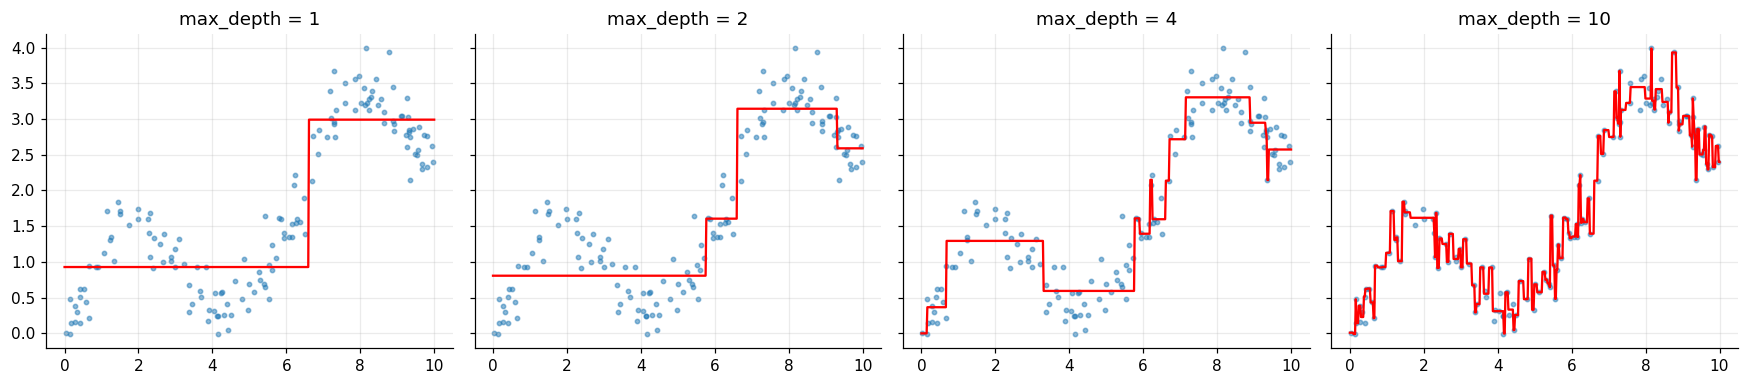

In [3]:
rng = np.random.default_rng(0)
x = np.sort(rng.uniform(0, 10, 150))
y = np.sin(x) + 0.3 * x + rng.normal(scale=0.25, size=150)
xs = np.linspace(0, 10, 500)[:, None]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)
for ax, d in zip(axes, [1, 2, 4, 10]):
    t = DecisionTreeRegressor(max_depth=d).fit(x[:, None], y)
    ax.scatter(x, y, s=8, alpha=0.5); ax.plot(xs, t.predict(xs), "r"); ax.set_title(f"max_depth = {d}")
plt.tight_layout(); plt.show()

### 2. Depth vs error: the overfitting curve

Training error keeps shrinking toward zero (each leaf can hold a single point), while validation error bottoms out and rises again.

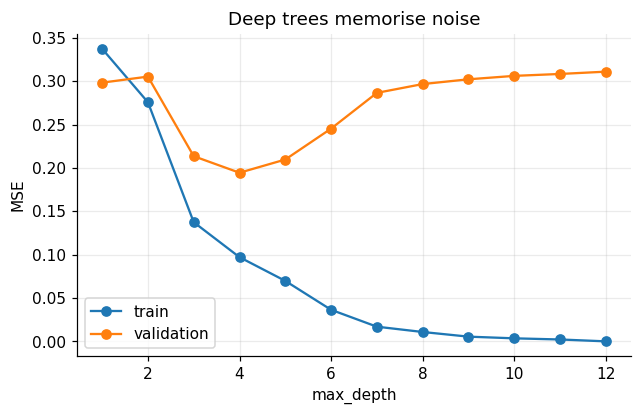

In [4]:
x2 = rng.uniform(0, 10, 300); y2 = np.sin(x2) + 0.3 * x2 + rng.normal(scale=0.4, size=300)
xtr, ytr, xva, yva = x2[:100], y2[:100], x2[100:], y2[100:]
depths = range(1, 13); tr, va = [], []
for d in depths:
    t = DecisionTreeRegressor(max_depth=d).fit(xtr[:, None], ytr)
    tr.append(np.mean((t.predict(xtr[:, None]) - ytr) ** 2)); va.append(np.mean((t.predict(xva[:, None]) - yva) ** 2))
plt.figure(figsize=(6.5, 3.8)); plt.plot(list(depths), tr, "o-", label="train"); plt.plot(list(depths), va, "o-", label="validation")
plt.xlabel("max_depth"); plt.ylabel("MSE"); plt.title("Deep trees memorise noise"); plt.legend(); plt.show()

### 3. Two features: rectangles

With two inputs the prediction surface is a mosaic of rectangles, one constant per leaf.

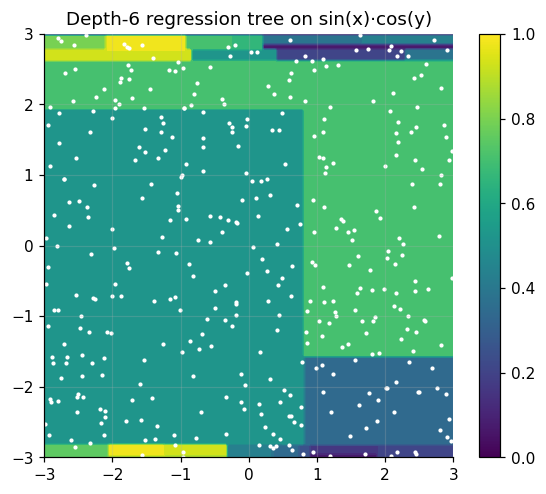

In [5]:
X2d = rng.uniform(-3, 3, size=(400, 2)); y2d = np.sin(X2d[:, 0]) * np.cos(X2d[:, 1]) + rng.normal(scale=0.1, size=400)
gx, gy = np.meshgrid(np.linspace(-3, 3, 150), np.linspace(-3, 3, 150))
t = DecisionTreeRegressor(max_depth=6).fit(X2d, y2d)
plt.figure(figsize=(6, 5)); plt.contourf(gx, gy, t.predict(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape), levels=20, cmap="viridis")
plt.scatter(*X2d.T, c="w", s=3); plt.title("Depth-6 regression tree on sin(x)·cos(y)"); plt.colorbar(); plt.show()

## Check against a reference implementation

Same data, same settings as scikit-learn (or scipy / the real library). The assertions fail if the two disagree.

In [6]:
import numpy as np
from sklearn.datasets import make_friedman1
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor as SklearnTree

X, y = make_friedman1(n_samples=500, noise=1.0, random_state=0)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

ours = DecisionTreeRegressor(max_depth=5).fit(X_train, y_train)
theirs = SklearnTree(max_depth=5, random_state=0).fit(X_train, y_train)

mse_ours = np.mean((ours.predict(X_test) - y_test) ** 2)
mse_theirs = np.mean((theirs.predict(X_test) - y_test) ** 2)
print("friedman1 test MSE: ours=%.4f sklearn=%.4f" % (mse_ours, mse_theirs))
assert abs(mse_ours - mse_theirs) / mse_theirs < 0.05

friedman1 test MSE: ours=10.1243 sklearn=10.1243


## Tests

Plain `assert` tests that check the invariants of the algorithm.

In [7]:
import numpy as np


def test_fits_step_function_exactly():
    X = np.array([[1.0], [2.0], [3.0], [10.0], [11.0], [12.0]])
    y = np.array([5.0, 5.0, 5.0, 20.0, 20.0, 20.0])
    assert np.allclose(DecisionTreeRegressor(max_depth=1).fit(X, y).predict(X), y)


def test_depth_zero_predicts_the_mean():
    X = np.arange(10.0).reshape(-1, 1)
    y = np.arange(10.0)
    assert np.allclose(DecisionTreeRegressor(max_depth=0).fit(X, y).predict(X), y.mean())


def test_predictions_are_piecewise_constant_and_deeper_fits_better():
    rng = np.random.default_rng(0)
    X = rng.uniform(0, 6, size=(300, 1))
    y = np.sin(X[:, 0]) + rng.normal(scale=0.05, size=300)
    shallow = DecisionTreeRegressor(max_depth=2).fit(X, y)
    deep = DecisionTreeRegressor(max_depth=6).fit(X, y)
    assert len(np.unique(shallow.predict(X))) <= 4  # 2**depth leaves at most
    assert np.mean((deep.predict(X) - y) ** 2) < np.mean((shallow.predict(X) - y) ** 2)

In [8]:
tests = [(name, fn) for name, fn in list(globals().items()) if name.startswith("test_") and callable(fn)]
for name, fn in tests:
    fn()
    print("PASS", name)
print(f"\nall {len(tests)} tests passed")

PASS test_fits_step_function_exactly
PASS test_depth_zero_predicts_the_mean
PASS test_predictions_are_piecewise_constant_and_deeper_fits_better

all 3 tests passed


## Takeaways

- **Use it when** you want a fast, interpretable non-linear model that needs no feature scaling and handles mixed feature types.
- **Splitting rule:** choose the (feature, threshold) maximising variance reduction; this folder does it with one sort and cumulative sums per feature (`O(n log n · d)`), not by re-evaluating each threshold from scratch.
- **Weaknesses:** staircase predictions, cannot extrapolate (constant outside the data range), high variance (small data changes alter the tree). Ensembles fix the variance: `18_bagging`, `19_random_forest`, `22_gradient_boosting`.
- **Interview line:** *"Greedy recursive splits that minimise within-leaf variance; each leaf predicts its mean; depth is the bias-variance knob."*